In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models 
import matplotlib.pyplot as plt

I0000 00:00:1793511215.661549    1907 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793511216.425948    1907 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793511220.441650    1907 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
dataset=tf.keras.preprocessing.image_dataset_from_directory(
   "potato_images",
    image_size=(256,256),
    batch_size=32,
    shuffle=True,
)

Found 2152 files belonging to 3 classes.


I0000 00:00:1793511229.373999    1907 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


In [23]:
class_names=dataset.class_names
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [25]:
len(dataset)

68

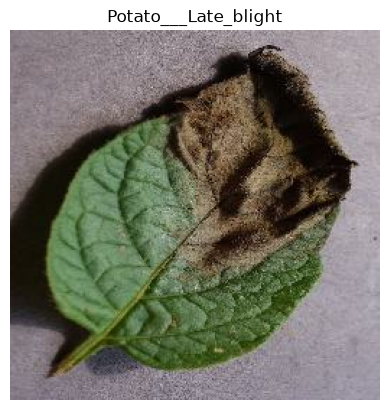

In [26]:
for image,label in dataset.take(1):
    # print(image)
    # print(label)
    plt.imshow(image[0].numpy().astype('uint8'))
    plt.title(class_names[label[0]])
    plt.axis('off')
    plt.show()

In [27]:
train_size=len(dataset)*0.8
train_dataset=dataset.take(int(train_size))
len(train_dataset)


54

In [28]:
test_ds=dataset.skip(int(train_size))
len(test_ds)

14

In [29]:
val_size=0.1
len(dataset)*val_size

6.800000000000001

In [30]:
val_ds=test_ds.take(6)

In [3]:
def get_dataset_partitions(
    ds,
    train_split=0.8,
    val_split=0.1,
    test_split=0.1,
    shuffle=True,
    shuffle_size=10000
):
    if shuffle:
        ds = ds.shuffle(buffer_size=shuffle_size, seed=12)

    dataset_size = len(ds)

    train_size = int(train_split * dataset_size)
    val_size = int(val_split * dataset_size)

    train_ds = ds.take(train_size)
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size + val_size)

    return train_ds, val_ds, test_ds

In [5]:
train_ds,val_ds,test_ds=get_dataset_partitions(dataset)

In [33]:
len(train_ds),len(val_ds),len(test_ds)

(54, 6, 8)

In [6]:
train_ds=train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds=val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds=test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

In [7]:
rescaling_layer=tf.keras.Sequential([
    layers.Resizing(256,256),
    layers.Rescaling(1./255)])

In [8]:
data_augmentation=tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2)
])

In [11]:
model = tf.keras.models.load_model("potato_model_v1.h5")

In [12]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_4 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 254, 254, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 127, 127, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 125, 125, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 60, 60, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,396,901 (28.22 MB)

 Trainable params: 7,396,899 (28.22 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [16]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy'])


In [18]:
history=model.fit(train_ds,
          validation_data=val_ds,
          epochs=50,
          batch_size=32)

Epoch 1/50


54/54 ━━━━━━━━━━━━━━━━━━━━ 7s 118ms/step - accuracy: 0.9971 - loss: 0.0092 - val_accuracy: 0.9792 - val_loss: 0.0509
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 116ms/step - accuracy: 0.9954 - loss: 0.0114 - val_accuracy: 1.0000 - val_loss: 0.0057
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - accuracy: 0.9965 - loss: 0.0107 - val_accuracy: 0.9688 - val_loss: 0.0632
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.9942 - loss: 0.0157 - val_accuracy: 0.9896 - val_loss: 0.0227
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - accuracy: 0.9890 - loss: 0.0347 - val_accuracy: 0.8750 - val_loss: 0.8461
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.9861 - loss: 0.0399 - val_accuracy: 0.9792 - val_loss: 0.0405
Epoch 7/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.9931 - loss: 0.0219 - val_accuracy: 1.0000 - val_loss: 0.0142
Epoch 8/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 112ms/step - accuracy: 0.9954 - loss: 0.0136 - val_accuracy: 1.0000 - val_loss

W0000 00:00:1793511576.466233    3272 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 41943296 bytes after encountering the first element of size 41943296 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - accuracy: 0.9959 - loss: 0.0186 - val_accuracy: 0.9531 - val_loss: 0.1293
Epoch 10/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 103ms/step - accuracy: 0.9919 - loss: 0.0205 - val_accuracy: 0.9948 - val_loss: 0.0160
Epoch 11/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 8s 152ms/step - accuracy: 0.9925 - loss: 0.0203 - val_accuracy: 0.9948 - val_loss: 0.0273
Epoch 12/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 186ms/step - accuracy: 0.9919 - loss: 0.0253 - val_accuracy: 1.0000 - val_loss: 0.0095
Epoch 13/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 12s 224ms/step - accuracy: 0.9740 - loss: 0.0738 - val_accuracy: 0.9635 - val_loss: 0.1301
Epoch 14/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 11s 198ms/step - accuracy: 0.9792 - loss: 0.0641 - val_accuracy: 0.9896 - val_loss: 0.0353
Epoch 15/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 11s 210ms/step - accuracy: 0.9907 - loss: 0.0222 - val_accuracy: 0.9271 - val_loss: 0.1894
Epoch 16/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 8s 148ms/step - accuracy: 0.9931 - loss: 0.0191 - val_accuracy: 0.

In [19]:
model.evaluate(test_ds)

W0000 00:00:1793511922.584152    3508 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 25166080 bytes after encountering the first element of size 25166080 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 80ms/step - accuracy: 0.9883 - loss: 0.0344


[0.0343673974275589, 0.98828125]

In [42]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

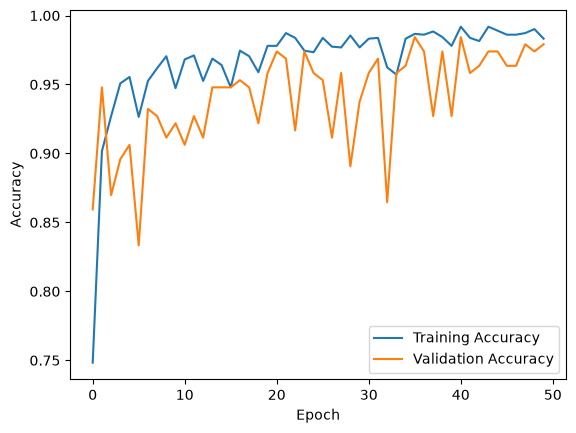

In [43]:

acc=history.history['accuracy']
val_acc=history.history['val_accuracy']
loss=history.history['loss']
val_loss=history.history['val_loss']
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

first image
first label: Potato___Late_blight
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 513ms/step
prediction: Potato___Late_blight


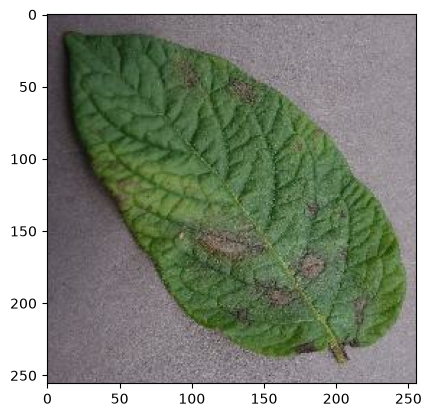

In [ ]:
#each batch contains 32 images and labels
import numpy as np

for image,batch in test_ds.take(1):
    first_image = image[31].numpy().astype('uint8')
    first_label = batch[31].numpy()
    plt.imshow(first_image)
    print("first image")
    print("first label:", class_names[first_label])
    prediction = model.predict(image)
    print("prediction:", class_names[np.argmax(prediction[31])])


In [28]:
def predict(model,img):
    img_array=tf.keras.preprocessing.image.img_to_array(img)
    img_array=tf.expand_dims(img_array,0)
    prediction=model.predict(img_array)
    confidence = round(float(np.max(prediction[0])) * 100, 2)
    return prediction, confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step


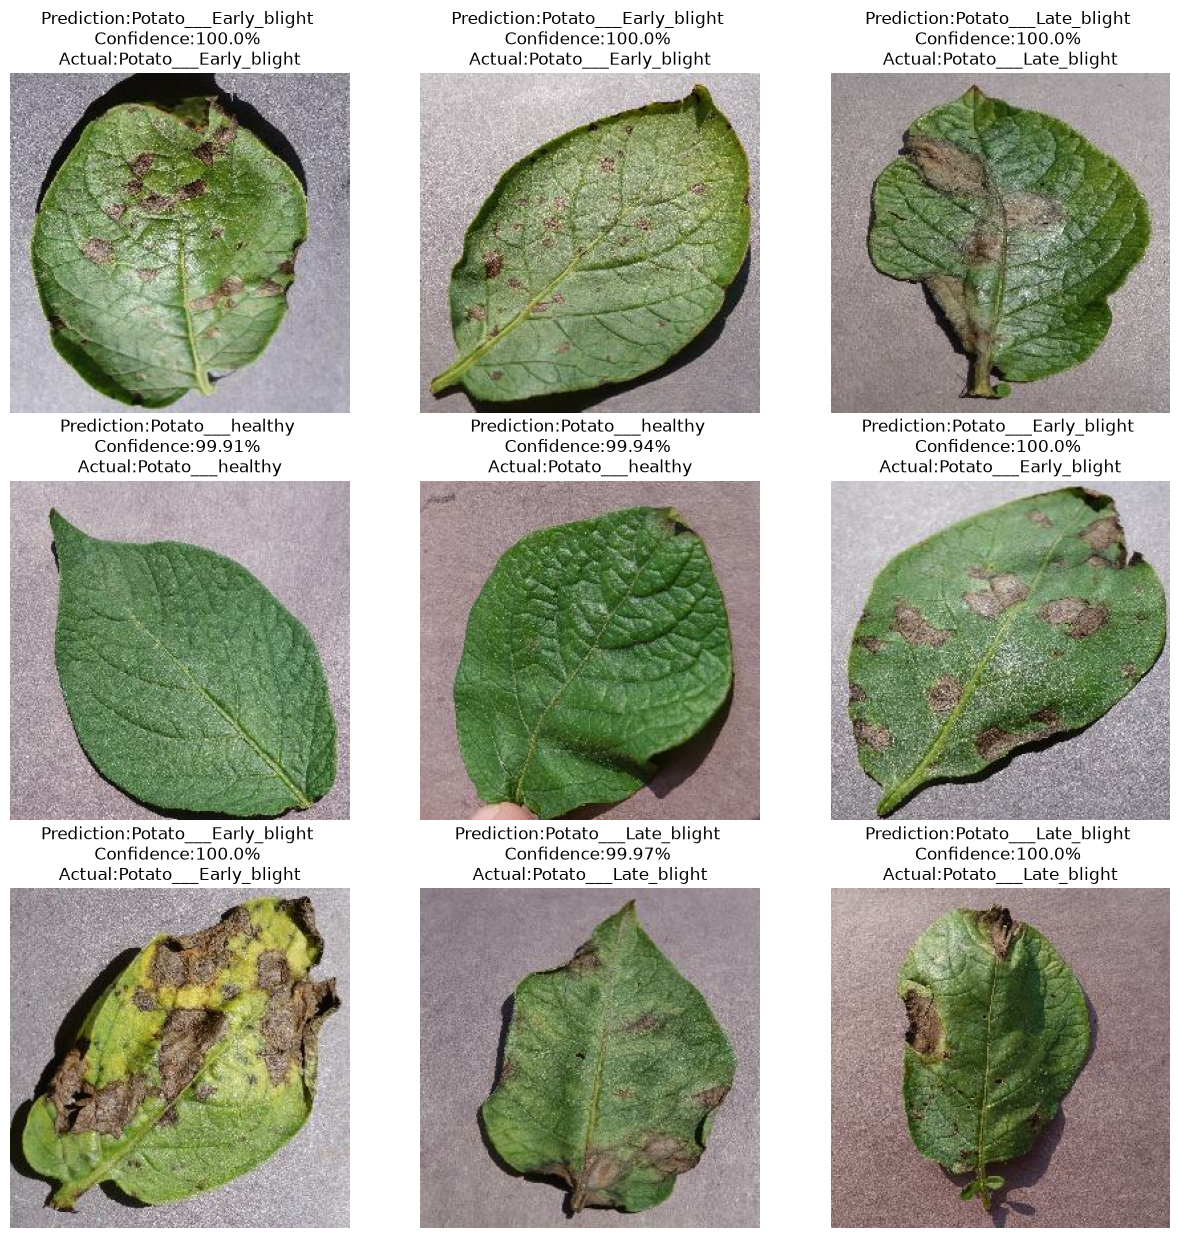

In [29]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,15))
for image,label in test_ds.take(1):
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(image[i].numpy().astype('uint8'))
        prediction,confidence=predict(model,image[i])
        actual_label=class_names[label[i]]
        plt.title(f"Prediction:{class_names[np.argmax(prediction[0])]} \nConfidence:{confidence}% \nActual:{actual_label}")
        plt.axis('off')

In [51]:
model_version=1
model.save(f"potato_model_v{model_version}.h5")

In [53]:

import os

print(os.path.exists("potato_model_v1.h5"))

True


In [10]:
import os

print("Current directory:", os.getcwd())
print("Files:", os.listdir())

Current directory: /home/manoj/deeplearning gpu/potato-disease
Files: ['potato_model_v1.h5', 'potato.ipynb', 'outputs', 'notebooks', 'src', 'models', 'potato_images', 'README.md', '.gitignore', '.git']
